In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler

import numpy as np
import torchvision
from torchvision import datasets, models, transforms
import matplotlib.pyplot as plt
import time
import os
import copy

In [2]:
import os
import shutil
from random import shuffle

# Paths to the dataset directory and the train/val directories
dataset_path = '/Users/Elizabeth/Desktop/ML/animals'
train_path = 'train'
val_path = 'val'

# Create train and val directories if they don't exist
os.makedirs(train_path, exist_ok=True)
os.makedirs(val_path, exist_ok=True)

# List all class directories in the dataset
class_directories = [d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d))]

# Iterate over each class directory
for class_dir in class_directories:
    class_path = os.path.join(dataset_path, class_dir)
    images = os.listdir(class_path)
    shuffle(images)  # Shuffle to randomize the files that go into train and val

    # Ensure the destination directories for the class exist
    train_class_path = os.path.join(train_path, class_dir)
    val_class_path = os.path.join(val_path, class_dir)
    os.makedirs(train_class_path, exist_ok=True)
    os.makedirs(val_class_path, exist_ok=True)

    # Move the first 40 images to the train directory and the rest to the val directory
    for i, image in enumerate(images):
        if i < 40:
            shutil.move(os.path.join(class_path, image), os.path.join(train_class_path, image))
        else:
            shutil.move(os.path.join(class_path, image), os.path.join(val_class_path, image))

In [2]:
data_dir = '/Users/Elizabeth/Desktop/ML/untitled folder'
train_dir = '/Users/Elizabeth/Desktop/ML/train'
val_dir = '/Users/Elizabeth/Desktop/ML/val'

In [3]:
data_transforms = {
    'train': transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
    'val': transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ]),
}


In [4]:
image_datasets = {x: datasets.ImageFolder(os.path.join(data_dir, x),
                                          data_transforms[x])
                  for x in ['train', 'val']}


In [5]:
dataloaders = {x: torch.utils.data.DataLoader(image_datasets[x], batch_size=4,
                                             shuffle=True, num_workers=4)
              for x in ['train', 'val']}


In [6]:
dataset_sizes = {x: len(image_datasets[x]) for x in ['train', 'val']}


In [7]:
class_names = image_datasets['train'].classes

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

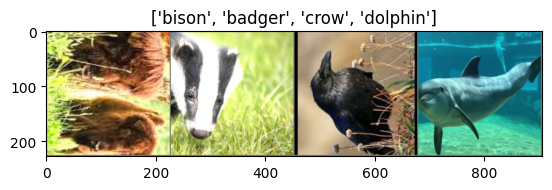

In [8]:
def imshow(inp, title=None):
    """Display image for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.pause(0.001)  # pause a bit so that plots are updated


# Get a batch of training data
inputs, classes = next(iter(dataloaders['train']))

# Make a grid from batch
out = torchvision.utils.make_grid(inputs)

imshow(out, title=[class_names[x] for x in classes])

In [9]:
def train_model(model, criterion, optimizer, scheduler, num_epochs=25):
    t1 = time.time()

    best_model_wts = copy.deepcopy(model.state_dict())
    best_acc = 0.0

    for epoch in range(num_epochs):
        print(f'Epoch {epoch}/{num_epochs - 1}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode
            else:
                model.eval()   # Set model to evaluate mode

            running_loss = 0.0
            running_corrects = 0

            # Iterate over data.
            for inputs, labels in dataloaders[phase]:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # zero the parameter gradients
                optimizer.zero_grad()

                # Forward
                # Track history if only in train
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # backward + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # statistics
                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)

            if phase == 'train':
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]

            print(f'{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}')

            # deep copy the model
            if phase == 'val' and epoch_acc > best_acc:
                best_acc = epoch_acc
                best_model_wts = copy.deepcopy(model.state_dict())

        print()

    time_elapsed = time.time() - t1
    print(f'Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best val Acc: {best_acc:4f}')

    # load best model weights
    model.load_state_dict(best_model_wts)
    return model

In [10]:
def visualize_model(model, num_images=6):
    was_training = model.training
    model.eval()
    images_so_far = 0
    fig = plt.figure()

    with torch.no_grad():
        for i, (inputs, labels) in enumerate(dataloaders['val']):
            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)

            for j in range(inputs.size()[0]):
                images_so_far += 1
                ax = plt.subplot(num_images//2, 2, images_so_far)
                ax.axis('off')
                ax.set_title(f'predicted: {class_names[preds[j]]}')
                imshow(inputs.cpu().data[j])

                if images_so_far == num_images:
                    model.train(mode=was_training)
                    return
        model.train(mode=was_training)

In [11]:
input_shape = 3
hidden_units = 64
block_1 = nn.Sequential(nn.Conv2d(in_channels=input_shape,
                                               out_channels=hidden_units,
                                               kernel_size=5, # how big is the square that's going over the image?
                                               stride=1, # default
                                               padding=1), # Options = "valid" (no padding) or "same" (the output has the same shape as the input) or int for specific number
                                     nn.BatchNorm2d(hidden_units,
                                                    eps=1e-05,
                                                    momentum=0.1,
                                                    affine=True,
                                                    track_running_stats=True),
                                     nn.ReLU(),
                                     nn.Conv2d(in_channels=hidden_units,
                                               out_channels=hidden_units,
                                               kernel_size=5,
                                               stride=1,
                                               padding=1),
                                     nn.BatchNorm2d(hidden_units,
                                                    eps=1e-05,
                                                    momentum=0.1,
                                                    affine=True,
                                                    track_running_stats=True),
                                     nn.ReLU(),
                                     nn.MaxPool2d(kernel_size=2, stride=2)
                                     )

block_2 = nn.Sequential(nn.Conv2d(in_channels=hidden_units,
                                               out_channels=hidden_units,
                                               kernel_size=5,
                                               padding=1),
                                     nn.BatchNorm2d(hidden_units,
                                                    eps=1e-05,
                                                    momentum=0.1,
                                                    affine=True,
                                                    track_running_stats=True),
                                     nn.ReLU(),
                                     nn.Conv2d(in_channels=hidden_units,
                                               out_channels=hidden_units,
                                               kernel_size=5,
                                               padding=1),
                                     nn.BatchNorm2d(hidden_units,
                                                    eps=1e-05,
                                                    momentum=0.1,
                                                    affine=True,
                                                    track_running_stats=True),
                                     nn.ReLU(),
                                     nn.MaxPool2d(kernel_size=2, stride=2)
        )


image = torch.randn(size=(1, 3, 224, 224)) # [batch_size, color_channels, height, width]

x = block_1(image)

x = block_2(x)

x.shape

torch.Size([1, 64, 53, 53])

In [12]:
model_transfer = models.resnet18(weights='IMAGENET1K_V1')

In [13]:
num_ftrs = model_transfer.fc.in_features
num_ftrs

512

In [14]:
for param in model_transfer.parameters():
    param.requires_grad = False

# The size of each output sample is set to 2.
# Alternatively, it can be generalized to ``nn.Linear(num_ftrs, len(class_names))``.
model_transfer.fc = nn.Linear(num_ftrs, 90)

model_transfer = model_transfer.to(device)

criterion = nn.CrossEntropyLoss()

# Observe that all parameters are being optimized
optimizer_transfer = optim.SGD(model_transfer.parameters(), lr=0.001, momentum=0.9)

# Decay LR by a factor of 0.1 every 10 epochs
exp_lr_scheduler = lr_scheduler.StepLR(optimizer_transfer, step_size=5, gamma=0.1)

In [ ]:
model_transfer = train_model(model_transfer, criterion, optimizer_transfer, exp_lr_scheduler, num_epochs=15)

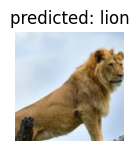

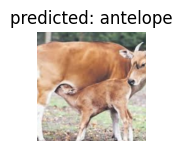

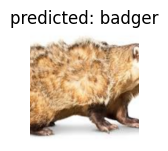

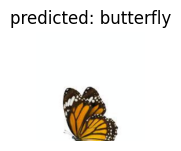

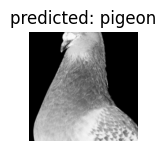

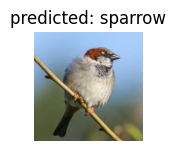

In [25]:
visualize_model(model_transfer)